In [ ]:
# optimizer imports
from tidyhebo import tidyHEBO
from tidyhebo import RealP, RealPowP, DiscreteRealP, IntegerP, CategoricalP, BoolP

# define parameter space
params = [
    IntegerP(0, 2, 6, name="log2_batch_size"),
    RealP(1, -5, -3, ds_tolerance=0.1, name="log10_lr"),
    DiscreteRealP(2, 1e-2, 1.5e-1, n=5, name="weight_decay"),
    DiscreteRealP(3, 0.1, 0.5, n=5, name="dropout"),
    CategoricalP(4, ["max", "avg"], name="pooling")
]

## to initialize from scratch
optimizer = tidyHEBO(params, n_init=8)  # n_init - how many initial samples to draw

## to initialize with existing data
import pandas as pd
import numpy as np

# At X order of columns and column names should batch with parameters passed to optimizer
x_known: pd.DataFrame = pd.read_csv("x_example.csv", index_col=0)  
# y in the form of 2d numpy array
y_known: np.ndarray = pd.read_csv("y_example.csv", index_col=0).values


# create optimizer
optimizer = tidyHEBO(parameters=params,
                          train_x=x_known,
                          train_y=y_known)

## suggest a new point to evaluate

In [12]:
# first suggestion might take a while; second and after should be faster
candidate: pd.DataFrame = optimizer.suggest()
candidate

,log2_batch_size,log10_lr,weight_decay,dropout,pooling
2406,2,-3.317227,0.15,0.5,avg


In [13]:
candidate.to_dict(orient="records")

[{'log2_batch_size': 2,
  'log10_lr': -3.3172270772809394,
  'weight_decay': 0.15,
  'dropout': 0.5,
  'pooling': 'avg'}]

## add new observations

In [9]:
optimizer.observe(X=candidate, y=np.array([0.0001, ]))

In [10]:
optimizer.suggest()

,log2_batch_size,log10_lr,weight_decay,dropout,pooling
915,6,-3.618598,0.01,0.4,avg


## save results

In [16]:
x_history = optimizer.design_space.from_GA_to_DS(optimizer.train_x, return_df=True)
y_history = optimizer.train_y

# Full optimization of a synthetic function

In [1]:
import matplotlib.pyplot as plt

In [5]:
from tidyhebo import tidyHEBO, RealP


import torch
from botorch.test_functions import Ackley


problem = Ackley(dim=2, negate=True)

params = [
    RealP(0, 0, 1),
    RealP(1, 0, 1),
]

optimizer = tidyHEBO(params, n_init=8)

/home/jnarbert/miniforge3/envs/tidyhebo3/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
for i in range(30):
    candidate = optimizer.suggest()

    x_new = torch.from_numpy(candidate.values)
    y_new = problem(x_new)

    optimizer.observe(candidate, y_new.detach().numpy())


In [7]:
optimzer_res = optimizer.train_y.cummax(axis=0).values

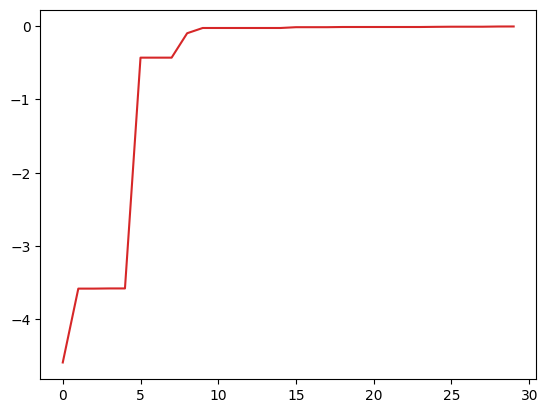

In [8]:
plt.plot(optimzer_res, label="tidyHEBO", c="tab:red")